In [3]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


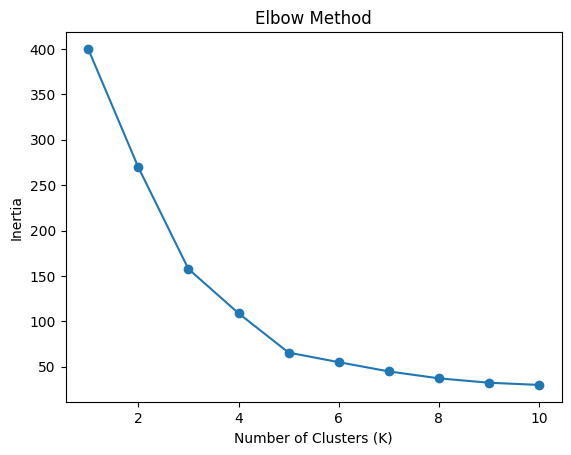

Cluster Labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 2 0 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3
 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 1 3 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3]
Final Centroids:
[[-0.6254061   0.01844024]
 [ 1.81769762 -1.12300187]
 [ 0.5460773  -1.27334719]
 [ 0.99158305  1.23950275]]
Number of iterations: 5
Algorithm stopped when centroids converged.


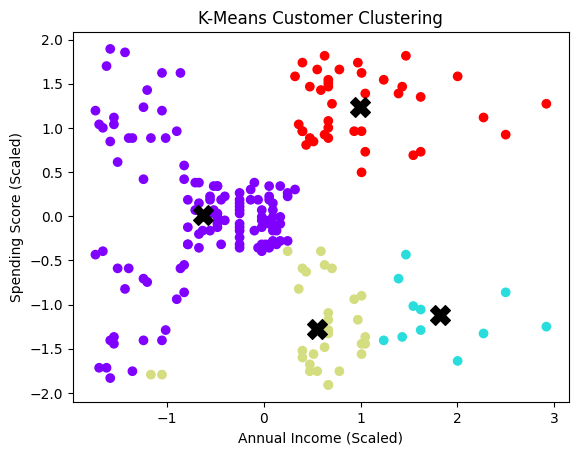

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load Kaggle dataset
data = pd.read_csv("Mall_Customers.csv")

# Select features
X = data[['Annual Income (k$)', 'Spending Score (1-100)']]

# Scale data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# 2. Decide number of clusters using Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# Choose K = 5
K = 4

# 3. Initialize centroids
kmeans = KMeans(n_clusters=K, init='random',
                n_init=1, random_state=42)

kmeans.fit(X)

# 4. Assign data points to clusters
labels = kmeans.labels_

print("Cluster Labels:")
print(labels)

# 5. Recalculate centroids
centroids = kmeans.cluster_centers_

print("Final Centroids:")
print(centroids)

# 6. Check whether centroids have converged
print("Number of iterations:", kmeans.n_iter_)
print("Algorithm stopped when centroids converged.")

# 7. Visualize clusters
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='rainbow')
plt.scatter(centroids[:, 0], centroids[:, 1],
            color='black', marker='X', s=200)

plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.title("K-Means Customer Clustering")
plt.show()